In [36]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [37]:
img1 = cv2.imread(r"D:\ComputerVision\p1.png")
img2 = cv2.imread(r"D:\ComputerVision\p2.png")
if img1 is None or img2 is None:
    raise ValueError(
        "One or both images could not be loaded."
    )
print("Both images loaded successfully.")

Both images loaded successfully.


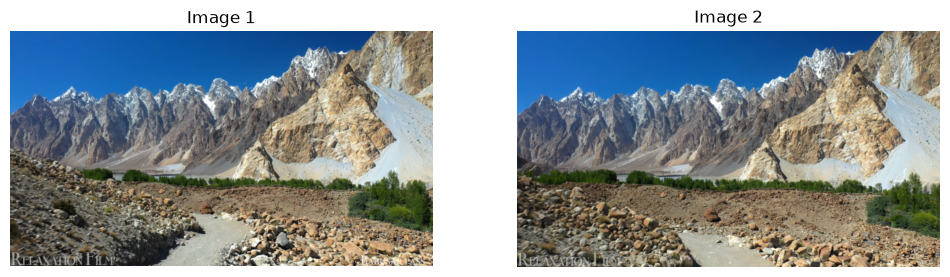

In [38]:
rgb1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
rgb2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(rgb1)
plt.title("Image 1")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(rgb2)
plt.title("Image 2")
plt.axis("off")
plt.show()

In [39]:
gray1 = cv2.cvtColor(rgb1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(rgb2, cv2.COLOR_RGB2GRAY)
orb = cv2.ORB_create(nfeatures=1500)
keypoints1, descriptors1 = orb.detectAndCompute(
    gray1,
    None
)
keypoints2, descriptors2 = orb.detectAndCompute(
    gray2,
    None
)
print("Image 1 Keypoints:", len(keypoints1))
print("Image 2 Keypoints:", len(keypoints2))

Image 1 Keypoints: 1500
Image 2 Keypoints: 1500


In [40]:
if descriptors1 is None or descriptors2 is None:
    raise ValueError(
        "Not enough features. Use clearer images."
    )
bf = cv2.BFMatcher(
    cv2.NORM_HAMMING,
    crossCheck=True
)
matches = bf.match(
    descriptors1,
    descriptors2
)
matches = sorted(
    matches,
    key=lambda x: x.distance
)
print("Total Matches:", len(matches))

Total Matches: 593


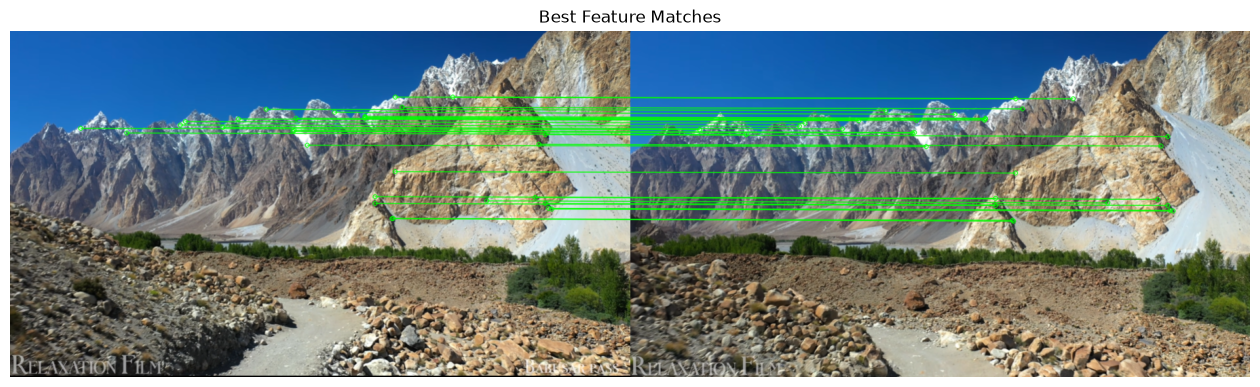

In [41]:
best_matches = matches[:30]
matched_output = cv2.drawMatches(
    rgb1,
    keypoints1,
    rgb2,
    keypoints2,
    best_matches,
    None,
    matchColor=(0, 255, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.figure(figsize=(16, 8))
plt.imshow(matched_output)
plt.title("Best Feature Matches")
plt.axis("off")
plt.show()

In [42]:
stitcher = cv2.Stitcher_create()
status, panorama = stitcher.stitch(
    [img1, img2]
)
if status == cv2.Stitcher_OK:
    print("Panorama created successfully.")
else:
    print("Stitching failed. Status code:", status)

Panorama created successfully.


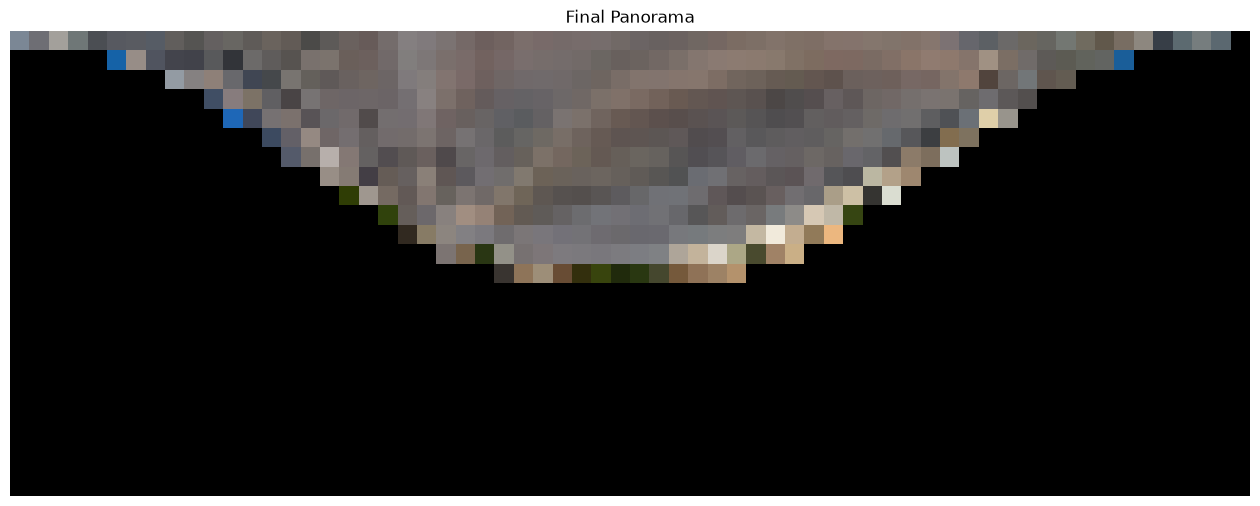

In [43]:
if status == cv2.Stitcher_OK:
    panorama_rgb = cv2.cvtColor(
        panorama,
        cv2.COLOR_BGR2RGB
    )
    plt.figure(figsize=(16, 8))
    plt.imshow(panorama_rgb)
    plt.title("Final Panorama")
    plt.axis("off")
    plt.show()

In [44]:
if status == cv2.Stitcher_OK:
    plt.imsave(
        "panorama_output.jpg",
        panorama_rgb
    )
    print("Panorama saved successfully.")

Panorama saved successfully.
